[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/02_algebra.ipynb)

*Math for Data Science & ML · Notebook 2 of 10*

# Algebra & Equations

Letters that stand for numbers: expressions, solving equations, quadratics, polynomials, systems of equations, inequalities and sequences.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** An equation is a balance scale: whatever you do to one side, you do to the other.

**What interviewers really test here:** Rearranging formulas and reading them, rather than memorising.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Variables and expressions *(Basics)*
- [ ] 2. Solving equations: keep the scales balanced *(Basics)*
- [ ] 3. Expanding and factorising *(Basics)*
- [ ] 4. Quadratic equations *(Core)*
- [ ] 5. Two equations, two unknowns *(Core)*
- [ ] 6. The quadratic formula, step by step *(Core)*
- [ ] 7. Rearranging formulas *(Core)*
- [ ] 8. Inequalities *(Core)*
- [ ] 9. Growth, sequences and solving with logs *(Advanced)*
- [ ] 10. Word problems, and when systems have no answer *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Vocabulary

| Word | Meaning | Example |
| --- | --- | --- |
| Variable | a letter standing for an unknown or changing number | x, y, w |
| Coefficient | the number multiplying a variable | 3 in 3x |
| Constant | a number on its own | 5 |
| Term | a constant, a variable, or their product | 4x² |
| Expression | terms joined by + or −, no "=" | 4x² − 3x + 5 |
| Equation | two expressions set equal | 2x + 3 = 11 |
| Polynomial | sum of terms with whole-number powers; degree = highest power | x³ − 2x + 1 (degree 3) |

### Solving equations

- **Linear** (degree 1): isolate x with inverse operations. ax + b = c ⇒ x = (c − b)/a.
- **Quadratic** (degree 2): factorise, complete the square, or use x = (−b ± √(b² − 4ac)) / 2a. Discriminant D = b² − 4ac.
- Sum of roots = −b/a, product = c/a (Vieta's formulas).
- Higher degree: no simple general formula for degree ≥ 5 — use numerical methods (bisection, Newton) or `np.roots`.
- **Inequalities** are solved like equations, except multiplying or dividing by a negative **flips** the sign.
- **Absolute value**: |x − a| = b splits into x − a = b or x − a = −b.

### Identities worth memorising

|   |
| --- |
| (a + b)² = a² + 2ab + b² |
| (a − b)² = a² − 2ab + b² |
| (a + b)(a − b) = a² − b² |
| (x + a)(x + b) = x² + (a + b)x + ab |



(a − b)² appears constantly in ML: the squared error between a prediction and a target.

### Systems of linear equations

A system can have **one** solution (lines cross), **none** (parallel lines) or **infinitely many** (same line). Methods: substitution, elimination, and matrices (A·x = b ⇒ x = A⁻¹b when A is invertible). Linear regression is a giant system with more equations than unknowns, solved in the "least squares" sense.

### Sequences and series

|   | Arithmetic | Geometric |
| --- | --- | --- |
| Rule | add d | multiply by r |
| n-th term | a + (n − 1)d | a·rⁿ⁻¹ |
| Sum of n terms | n(2a + (n − 1)d)/2 | a(1 − rⁿ)/(1 − r) |
| Infinite sum | diverges (d ≠ 0) | a/(1 − r) if \|r\| &lt; 1 |

---
# Part 2: Lessons, step by step

## Lesson 1: Variables and expressions

*Level: Basics*

Algebra is arithmetic with **unknowns**. A letter like x is a box that holds a number we don't know yet — exactly like a variable in Python.




- An **expression** is a recipe: 3x + 2 means "multiply x by 3, then add 2". It has no equals sign.
- To **evaluate** it, substitute a number: if x = 4, 3x + 2 = 14.
- **Like terms** have the same letter and power and can be combined: 3x + 5x = 8x, but 3x + 5x² cannot.
- 3x means 3 × x; x² means x × x; 2(x + 1) = 2x + 2 (the distributive rule).



In ML, a model like *price = 3000 × size + 20000* is an expression: size is the input, 3000 and 20000 are numbers the model learns.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [2]:
def expressions_demo():
    x = 4
    expression = 3 * x + 2
    size = 80
    price = 3000 * size + 20000
    like_terms = 3 * x + 5 * x
    same_as = 8 * x


expressions_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q8](#q8), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 2: Solving equations: keep the scales balanced

*Level: Basics*

An **equation** says two things are equal: 2x + 3 = 11. Think of a balance scale — whatever you do to one side, do to the other, and it stays balanced.



```python
2x + 3 = 11
2x     = 8      (subtract 3 from both sides)
 x     = 4      (divide both sides by 2)
```



**Check** by substituting back: 2·4 + 3 = 11 ✓. Undo operations in reverse order: the last thing done to x is undone first.



Variables on both sides: 3x + 4 = x + 10 → 2x = 6 → x = 3. Gather the x's on one side and the numbers on the other.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def balance_demo():
    left_coeff, left_const, right = 2, 3, 11
    right = right - left_const
    left_const = 0
    x = right / left_coeff
    check = 2 * x + 3


balance_demo()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q11](#q11), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 3: Expanding and factorising

*Level: Basics*

#### Expanding: multiply everything by everything



(x + 3)(x + 2): each term in the first bracket multiplies each term in the second.



|   | x | +2 |
| --- | --- | --- |
| x | x² | 2x |
| +3 | 3x | 6 |



Add them up: x² + 5x + 6.



#### Factorising: go backwards



For x² + 5x + 6, find two numbers that **multiply to 6 and add to 5**: 2 and 3. So it equals (x + 2)(x + 3).



**Why bother?** If (x + 2)(x + 3) = 0, one bracket must be 0, so x = −2 or x = −3. That solved the equation.



#### Patterns to know



|   |   |
| --- | --- |
| (a + b)² = a² + 2ab + b² | (3 + 4)² = 9 + 24 + 16 = 49 ✓ |
| (a − b)² = a² − 2ab + b² | this is squared error |
| a² − b² = (a + b)(a − b) | 9 − 4 = 5 × 1 ✓ |



**The most common mistake:** (a + b)² = a² + b². It leaves out 2ab.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def expand_check():
    coefficients = np.polymul([1, 3], [1, 2])
    roots = np.sort(np.roots(coefficients))
    x = 7
    same = ((x + 3) * (x + 2), x ** 2 + 5 * x + 6)
    a, b = 3, 4
    correct = ((a + b) ** 2, a ** 2 + 2 * a * b + b ** 2)
    wrong = a ** 2 + b ** 2


expand_check()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q16](#q16), [Q7](#q7), [Q8](#q8), [Q14](#q14). Try one now, or carry on and do them in Part 3.

## Lesson 4: Quadratic equations

*Level: Core*

A **quadratic** has an x²: ax² + bx + c = 0. Its graph is a U-shaped curve called a **parabola**, and the solutions are where the curve crosses the x-axis.



The **discriminant** D = b² − 4ac tells you how many crossings:



| D | Solutions |
| --- | --- |
| &gt; 0 | two |
| = 0 | one (touches) |
| &lt; 0 | none (real) |



The **quadratic formula** gives them: x = (−b ± √D) / 2a.



Expanding (x + 2)(x + 3) = x² + 5x + 6 and factorising go in opposite directions; the factors show the roots straight away: x = −2 or x = −3.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

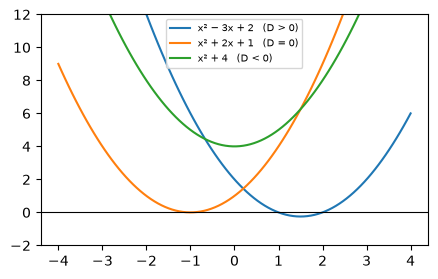

In [5]:
def parabolas():
    x = np.linspace(-4, 4, 100)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(x, x ** 2 - 3 * x + 2, label="x² − 3x + 2   (D > 0)")
    ax.plot(x, x ** 2 + 2 * x + 1, label="x² + 2x + 1   (D = 0)")
    ax.plot(x, x ** 2 + 4, label="x² + 4   (D < 0)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylim(-2, 12)
    ax.legend(fontsize=7)


parabolas()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q15](#q15), [Q6](#q6), [Q16](#q16), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 5: Two equations, two unknowns

*Level: Core*

One equation with two unknowns has infinitely many answers. Two equations usually pin down exactly one: the point where two lines cross.



```python
2x + y = 5
 x − y = 1
------------  add them: y cancels
3x     = 6   →  x = 2,  then y = 1
```



This is **elimination**. Later you will write the same system as a matrix equation A·v = c and let NumPy solve it — the same idea scales to thousands of unknowns, which is what fitting a linear regression does.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

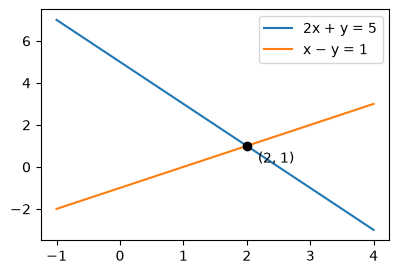

In [6]:
def two_lines():
    x = np.linspace(-1, 4, 50)
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(x, 5 - 2 * x, label="2x + y = 5")
    ax.plot(x, x - 1, label="x − y = 1")
    ax.plot(2, 1, "ko")
    ax.annotate("(2, 1)", (2, 1), xytext=(8, -12), textcoords="offset points")
    ax.legend()


two_lines()

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 6: The quadratic formula, step by step

*Level: Core*

Solve 2x² − 4x − 6 = 0.



1. **Read off:** a = 2, b = −4, c = −6.
2. **Discriminant:** D = b² − 4ac = 16 + 48 = 64.
3. **Formula:** x = (−b ± √D) / 2a = (4 ± 8) / 4.
4. **Two answers:** x = 12/4 = **3** or x = −4/4 = **−1**.
5. **Check:** 2(9) − 4(3) − 6 = 0 ✓ and 2(1) + 4 − 6 = 0 ✓.



#### Where the formula comes from



Take x² + bx + c = 0 (a = 1). Half of b, squared, completes a square:



```python
x² + bx        = −c
x² + bx + b²/4 = b²/4 − c
(x + b/2)²     = b²/4 − c
x = −b/2 ± √(b²/4 − c)
```



That's the same formula with a = 1. So x = −b/2a is the middle of the parabola, and ±√D / 2a is how far each root sits from it. This is also why the vertex is at x = −b/2a.



**Slip to avoid:** with b = −4, −b is +4, and b² is +16.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

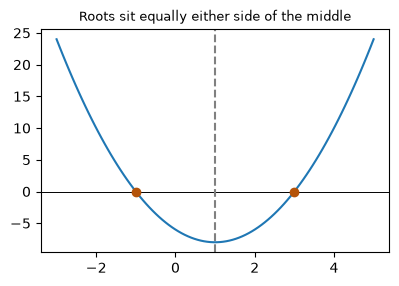

In [7]:
def quadratic_steps():
    a, b, c = 2, -4, -6
    discriminant = b ** 2 - 4 * a * c
    root = math.sqrt(discriminant)
    x1, x2 = (-b + root) / (2 * a), (-b - root) / (2 * a)
    checks = (a * x1 ** 2 + b * x1 + c, a * x2 ** 2 + b * x2 + c)
    middle = -b / (2 * a)
    xs = np.linspace(-3, 5, 100)
    fig, ax = plt.subplots(figsize=(4.5, 2.9))
    ax.plot(xs, a * xs ** 2 + b * xs + c)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.plot([x1, x2], [0, 0], "o", color="#b45309")
    ax.axvline(middle, ls="--", color="gray")
    ax.set_title("Roots sit equally either side of the middle", fontsize=9)


quadratic_steps()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 7: Rearranging formulas

*Level: Core*

Treat every letter like a number. Undo what was done to your target, in reverse order.



| Start | Make the subject | Steps | Result |
| --- | --- | --- | --- |
| y = mx + c | x | subtract c, divide by m | x = (y − c) / m |
| F = 9C/5 + 32 | C | subtract 32, multiply by 5/9 | C = 5(F − 32) / 9 |
| z = (x − μ) / σ | x | multiply by σ, add μ | x = μ + zσ |
| A = P(1 + r)ⁿ | r | divide by P, take n-th root, subtract 1 | r = (A/P)^(1/n) − 1 |



#### Check with numbers



F = 212 gives C = 5(180)/9 = 100. Water boils at 100°C ✓. Trying a value you know is the quickest way to catch mistakes.



#### Equations with fractions



x/3 + 2 = 5 → x/3 = 3 → **x = 9**. Multiply by the bottom to clear a fraction, after moving other terms away.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [8]:
def rearrange_checks():
    f = 212
    c = 5 * (f - 32) / 9
    back_to_f = 9 * c / 5 + 32
    mu, sigma, z = 70, 10, 1.5
    x = mu + z * sigma
    back_to_z = (x - mu) / sigma
    growth_rate = (1210 / 1000) ** (1 / 2) - 1


rearrange_checks()

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q2](#q2), [Q3](#q3), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 8: Inequalities

*Level: Core*

Solve them like equations, with one extra rule: **multiplying or dividing by a negative flips the sign.**



#### Worked example



```python
−2x + 1 > 5
−2x     > 4        subtract 1
  x     < −2       divide by −2, so flip
```



**Check** with x = −3: −2(−3) + 1 = 7, and 7 &gt; 5 ✓. With x = 0: 1 &gt; 5 is false ✓.



**Why flip?** 2 &lt; 3, but multiplying by −1 gives −2 &gt; −3: the number line is mirrored.



#### Absolute value



- |x − 3| = 2 means x is 2 away from 3: x = 1 or x = 5.
- |x − 3| &lt; 2 means **closer** than 2: 1 &lt; x &lt; 5.



In data science, every filter such as `df[df.age > 30]` or a tree's "x ≤ 3.5" is an inequality.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [9]:
def inequality_checks():
    xs = np.arange(-5, 3)
    works = xs[-2 * xs + 1 > 5]
    formula_says = xs[xs < -2]
    within_two = np.arange(0, 7)[np.abs(np.arange(0, 7) - 3) < 2]


inequality_checks()

**✏️ Your turn:** you now have what you need for [Q9](#q9), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 9: Growth, sequences and solving with logs

*Level: Advanced*

An **arithmetic sequence** adds the same amount each step (3, 7, 11, …): aₙ = a₁ + (n−1)d. A **geometric sequence** multiplies by the same amount (1, 2, 4, 8, …): aₙ = a₁·rⁿ⁻¹.



Money with interest grows geometrically: P(1 + r)ⁿ. To ask "how many years until it doubles?" you must get n out of the exponent — that is what a **logarithm** does: n = log 2 / log(1 + r). (Logs are explained properly in the next topic.)



When no formula exists, you can still solve f(x) = 0 by **bisection**: keep halving an interval where f changes sign. Numerical methods like this are how computers solve the equations in ML.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

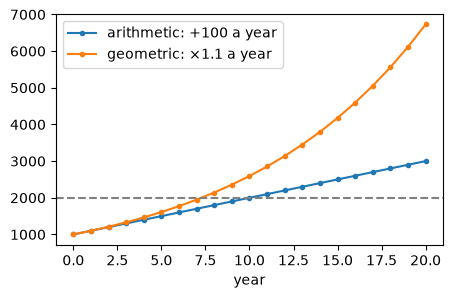

In [10]:
def growth_demo():
    years = np.arange(0, 21)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.plot(years, 1000 + 100 * years, "o-", markersize=3, label="arithmetic: +100 a year")
    ax.plot(years, 1000 * 1.1 ** years, "o-", markersize=3, label="geometric: ×1.1 a year")
    ax.axhline(2000, color="gray", linestyle="--")
    ax.set_xlabel("year")
    ax.legend()


growth_demo()

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q20](#q20), [Q12](#q12), [Q18](#q18), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 10: Word problems, and when systems have no answer

*Level: Advanced*

#### From words to equations



"5 fruits cost ₹13. Apples cost ₹3 and oranges ₹2. How many of each?"



1. **Name the unknowns:** a apples, o oranges.
2. **Write what's known:** a + o = 5 and 3a + 2o = 13.
3. **Eliminate:** multiply the first by 2: 2a + 2o = 10. Subtract: a = 3.
4. **Substitute:** o = 2.
5. **Check:** 3(3) + 2(2) = 13 ✓.



#### Three possible outcomes



| Lines | Solutions | Example |
| --- | --- | --- |
| Cross | one | y = x, y = −x + 2 |
| Parallel | none | y = x, y = x + 2 |
| Same line | infinitely many | y = x, 2y = 2x |



**In ML:** real data has more equations than unknowns and no exact answer, so linear regression finds the closest one. With duplicate features, you get the "same line" case: many equally good answers, which regularisation resolves.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

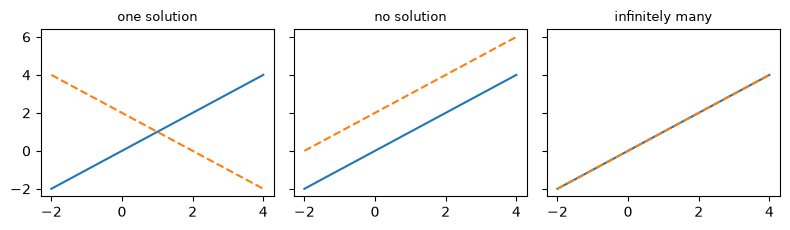

In [11]:
def three_cases():
    apples_oranges = np.linalg.solve([[1, 1], [3, 2]], [5, 13])
    x = np.linspace(-2, 4, 10)
    fig, axes = plt.subplots(1, 3, figsize=(8, 2.4), sharey=True)
    cases = [("one solution", x, -x + 2), ("no solution", x, x + 2), ("infinitely many", x, x)]
    for ax, (name, first, second) in zip(axes, cases):
        ax.plot(x, first, label="line 1")
        ax.plot(x, second, "--", label="line 2")
        ax.set_title(name, fontsize=9)
    fig.tight_layout()


three_cases()

**✏️ Your turn:** you now have what you need for [Q17](#q17). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Evaluate a Polynomial

🟢 Warm-up · *Substitution*

Given coefficients (highest power first) and x, return the value. [3, 2, -5] at x = 2 → 3·4 + 2·2 − 5 = 11.

**Examples**

- `coeffs = [3, 2, -5], x = 2` → `11`
- `coeffs = [1, 0, 0, 1], x = -1` → `0`
- `coeffs = [5], x = 9` → `5`

In [ ]:
def evaluate(coeffs, x):
    """
    Given coefficients (highest power first) and x, return the value. [3, 2, -5]
    at x = 2 → 3·4 + 2·2 − 5 = 11.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(evaluate, [
    (([3, 2, -5], 2), 11),
    (([1, 0, 0, 1], -1), 0),
    (([5], 9), 5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Substitute: for each term compute coefficient × x^power and add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Horner's rule `np.polyval`: ((3)x + 2)x − 5 — only n multiplications.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Substitute: for each term compute coefficient × x^power and add.

```python
def evaluate(coeffs, x):
    n = len(coeffs) - 1
    total = 0
    for i, c in enumerate(coeffs):
        power = n - i
        term = c * x ** power
        total += term
    return total
```

**Cost:** O(n²) multiplications time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Horner's rule `np.polyval`: ((3)x + 2)x − 5 — only n multiplications.

```python
def evaluate(coeffs, x):
    return np.polyval(coeffs, x)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Substitute: for each term compute coefficient × x^power and add. That costs O(n²) multiplications time and O(1) space."

"I can do better: Horner's rule `np.polyval`: ((3)x + 2)x − 5 — only n multiplications. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/evaluate-a-polynomial)

<a id="q2"></a>
### Q2. Solve a Linear Equation

🟢 Warm-up · *ax + b = c*

Return x that solves a·x + b = c (a ≠ 0), rounded to 4 decimals.

**Examples**

- `a = 2, b = 3, c = 11` → `4.0`
- `a = 5, b = -2, c = 0` → `0.4`
- `a = -3, b = 6, c = 0` → `2.0`

In [ ]:
def solve_linear(a, b, c):
    """
    Return x that solves a·x + b = c (a ≠ 0), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(solve_linear, [
    ((2, 3, 11), 4.0),
    ((5, -2, 0), 0.4),
    ((-3, 6, 0), 2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Do the same thing to both sides: subtract b, then divide by a — one step at a time.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula x = (c − b) / a.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Do the same thing to both sides: subtract b, then divide by a — one step at a time.

```python
def solve_linear(a, b, c):
    right = c
    right = right - b
    x = right / a
    return round(x, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula x = (c − b) / a.

```python
def solve_linear(a, b, c):
    return round((c - b) / a, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Do the same thing to both sides: subtract b, then divide by a — one step at a time. That costs O(1) time and O(1) space."

"I can do better: Formula x = (c − b) / a. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/solve-a-linear-equation)

<a id="q3"></a>
### Q3. Variables on Both Sides

🟢 Warm-up · *ax + b = cx + d*

Solve a·x + b = c·x + d (a ≠ c), rounded to 4 decimals.

**Examples**

- `a = 3, b = 4, c = 1, d = 10` → `3.0`
- `a = 5, b = -1, c = 2, d = 8` → `3.0`
- `a = 1, b = 0, c = -1, d = 3` → `1.5`

In [ ]:
def both_sides(a, b, c, d):
    """
    Solve a·x + b = c·x + d (a ≠ c), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(both_sides, [
    ((3, 4, 1, 10), 3.0),
    ((5, -1, 2, 8), 3.0),
    ((1, 0, -1, 3), 1.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Collect x terms on the left (subtract cx), numbers on the right (subtract b), then divide.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula x = (d − b) / (a − c).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Collect x terms on the left (subtract cx), numbers on the right (subtract b), then divide.

```python
def both_sides(a, b, c, d):
    x_coeff = a - c
    number = d - b
    return round(number / x_coeff, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula x = (d − b) / (a − c).

```python
def both_sides(a, b, c, d):
    return round((d - b) / (a - c), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Collect x terms on the left (subtract cx), numbers on the right (subtract b), then divide. That costs O(1) time and O(1) space."

"I can do better: Formula x = (d − b) / (a − c). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/variables-on-both-sides)

<a id="q4"></a>
### Q4. Rearrange a Formula

🟢 Warm-up · *Make y the subject*

Given a·x + b·y = c and a value of x, return y (b ≠ 0), rounded to 4 decimals.

**Examples**

- `a = 2, b = 3, c = 12, x = 3` → `2.0`
- `a = 1, b = -1, c = 4, x = 10` → `6.0`
- `a = 4, b = 2, c = 0, x = 1` → `-2.0`

In [ ]:
def make_y_subject(a, b, c, x):
    """
    Given a·x + b·y = c and a value of x, return y (b ≠ 0), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(make_y_subject, [
    ((2, 3, 12, 3), 2.0),
    ((1, -1, 4, 10), 6.0),
    ((4, 2, 0, 1), -2.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Move ax across (subtract it), then divide by b.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

y = (c − a·x) / b — vectorise it to get many points of the line at once.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Move ax across (subtract it), then divide by b.

```python
def make_y_subject(a, b, c, x):
    remaining = c - a * x
    y = remaining / b
    return round(y, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** y = (c − a·x) / b — vectorise it to get many points of the line at once.

```python
def make_y_subject(a, b, c, x):
    return round(float((c - a * np.asarray(x)) / b), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Move ax across (subtract it), then divide by b. That costs O(1) time and O(1) space."

"I can do better: y = (c − a·x) / b — vectorise it to get many points of the line at once. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/rearrange-a-formula)

<a id="q5"></a>
### Q5. How Many Real Solutions?

🟢 Warm-up · *The discriminant*

For ax² + bx + c = 0, return how many real solutions there are (0, 1 or 2).

**Examples**

- `a = 1, b = -3, c = 2` → `2`
- `a = 1, b = 2, c = 1` → `1`
- `a = 1, b = 0, c = 4` → `0`

In [ ]:
def num_solutions(a, b, c):
    """
    For ax² + bx + c = 0, return how many real solutions there are (0, 1 or 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(num_solutions, [
    ((1, -3, 2), 2),
    ((1, 2, 1), 1),
    ((1, 0, 4), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute b² − 4ac and test the sign with if/elif.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.sign` maps negative/zero/positive to −1/0/1; add 1.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compute b² − 4ac and test the sign with if/elif.

```python
def num_solutions(a, b, c):
    disc = b * b - 4 * a * c
    if disc > 0:
        return 2
    elif disc == 0:
        return 1
    else:
        return 0
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.sign` maps negative/zero/positive to −1/0/1; add 1.

```python
def num_solutions(a, b, c):
    return int(np.sign(b * b - 4 * a * c)) + 1
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute b² − 4ac and test the sign with if/elif. That costs O(1) time and O(1) space."

"I can do better: `np.sign` maps negative/zero/positive to −1/0/1; add 1. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/how-many-real-solutions)

<a id="q6"></a>
### Q6. Expand Two Brackets

🟢 Warm-up · *(x + a)(x + b)*

Return the coefficients of (x + a)(x + b) as [1, a + b, a·b].

**Examples**

- `a = 2, b = 3` → `[1, 5, 6]`
- `a = -1, b = 1` → `[1, 0, -1]`
- `a = -4, b = -4` → `[1, -8, 16]`

In [ ]:
def expand(a, b):
    """
    Return the coefficients of (x + a)(x + b) as [1, a + b, a·b].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(expand, [
    ((2, 3), [1, 5, 6]),
    ((-1, 1), [1, 0, -1]),
    ((-4, -4), [1, -8, 16]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

FOIL: First x·x, Outer x·b, Inner a·x, Last a·b — then collect like terms.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polymul([1, a], [1, b])`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** FOIL: First x·x, Outer x·b, Inner a·x, Last a·b — then collect like terms.

```python
def expand(a, b):
    first = 1
    outer = b
    inner = a
    last = a * b
    return [first, outer + inner, last]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polymul([1, a], [1, b])`.

```python
def expand(a, b):
    return np.polymul([1, a], [1, b])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: FOIL: First x·x, Outer x·b, Inner a·x, Last a·b — then collect like terms. That costs O(1) time and O(1) space."

"I can do better: `np.polymul([1, a], [1, b])`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/expand-two-brackets)

<a id="q7"></a>
### Q7. Add Two Polynomials

🟢 Warm-up · *Like terms*

Add two polynomials (highest power first). Lists may have different lengths.

**Examples**

- `p = [1, 2, 3], q = [4, 5]` → `[1, 6, 8]`
- `p = [2, 0], q = [-2, 1]` → `[0, 1]`
- `p = [5], q = [1, 1, 1]` → `[1, 1, 6]`

In [ ]:
def poly_add(p, q):
    """
    Add two polynomials (highest power first). Lists may have different lengths.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(poly_add, [
    (([1, 2, 3], [4, 5]), [1, 6, 8]),
    (([2, 0], [-2, 1]), [0, 1]),
    (([5], [1, 1, 1]), [1, 1, 6]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pad the shorter list with zeros on the left so the powers line up, then add position by position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polyadd(p, q)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Pad the shorter list with zeros on the left so the powers line up, then add position by position.

```python
def poly_add(p, q):
    n = max(len(p), len(q))
    p = [0] * (n - len(p)) + list(p)
    q = [0] * (n - len(q)) + list(q)
    return [a + b for a, b in zip(p, q)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polyadd(p, q)`.

```python
def poly_add(p, q):
    return np.polyadd(p, q)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pad the shorter list with zeros on the left so the powers line up, then add position by position. That costs O(n) time and O(n) space."

"I can do better: `np.polyadd(p, q)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/add-two-polynomials)

<a id="q8"></a>
### Q8. Collect Like Terms

🟢 Warm-up · *Simplifying*

Terms are (coefficient, power) pairs. Combine like powers and return {power: coefficient}, dropping zeros, highest power first.

**Examples**

- `terms = [(3, 2), (2, 1), (-1, 2), (5, 0), (-2, 1)]` → `{2: 2, 0: 5}`
- `terms = [(1, 1), (1, 1)]` → `{1: 2}`

In [ ]:
def like_terms(terms):
    """
    Terms are (coefficient, power) pairs. Combine like powers and return {power:
    coefficient}, dropping zeros, highest power first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(like_terms, [
    (([(3, 2), (2, 1), (-1, 2), (5, 0), (-2, 1)],), {2: 2, 0: 5}),
    (([(1, 1), (1, 1)],), {1: 2}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add each coefficient into a dictionary keyed by its power.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Scatter-add with NumPy: `np.add.at(coeffs, powers, values)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add each coefficient into a dictionary keyed by its power.

```python
def like_terms(terms):
    combined = {}
    for coef, pw in terms:
        combined[pw] = combined.get(pw, 0) + coef
    return {p: c for p, c in sorted(combined.items(), reverse=True) if c != 0}
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Scatter-add with NumPy: `np.add.at(coeffs, powers, values)`.

```python
def like_terms(terms):
    t = np.array(terms)
    coeffs = np.zeros(t[:, 1].max() + 1, dtype=int)
    np.add.at(coeffs, t[:, 1], t[:, 0])
    return {int(p): int(coeffs[p]) for p in range(len(coeffs) - 1, -1, -1) if coeffs[p] != 0}
```

**Cost:** O(n + max power) time, O(max power) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add each coefficient into a dictionary keyed by its power. That costs O(n log n) time and O(n) space."

"I can do better: Scatter-add with NumPy: `np.add.at(coeffs, powers, values)`. That's O(n + max power) time and O(max power) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/collect-like-terms)

<a id="q9"></a>
### Q9. Which Values Satisfy an Inequality?

🟢 Warm-up · *ax + b &gt; c*

Return the values from xs that make a·x + b &gt; c true.

**Examples**

- `xs = [0, 1, 2, 3, 4, 5], a = 2, b = 1, c = 6` → `[3, 4, 5]`
- `xs = [-2, -1, 0, 1], a = -1, b = 0, c = 0` → `[-2, -1]`

In [ ]:
def satisfies(xs, a, b, c):
    """
    Return the values from xs that make a·x + b > c true.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(satisfies, [
    (([0, 1, 2, 3, 4, 5], 2, 1, 6), [3, 4, 5]),
    (([-2, -1, 0, 1], -1, 0, 0), [-2, -1]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Test each value in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Boolean mask: `xs[a * xs + b > c]`. (Solving by hand: x &gt; (c − b)/a, and flip the sign if a &lt; 0.)

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Test each value in a loop.

```python
def satisfies(xs, a, b, c):
    out = []
    for x in xs:
        if a * x + b > c:
            out.append(x)
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Boolean mask: `xs[a * xs + b > c]`. (Solving by hand: x &gt; (c − b)/a, and flip the sign if a &lt; 0.)

```python
def satisfies(xs, a, b, c):
    xs = np.array(xs)
    return xs[a * xs + b > c]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Test each value in a loop. That costs O(n) time and O(n) space."

"I can do better: Boolean mask: `xs[a * xs + b > c]`. (Solving by hand: x &gt; (c − b)/a, and flip the sign if a &lt; 0.) That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/which-values-satisfy-an-inequality)

<a id="q10"></a>
### Q10. Absolute Value Equation

🟢 Warm-up · *|x − a| = b*

Return the solutions of |x − a| = b sorted ascending (b may be negative: then none).

**Examples**

- `a = 3, b = 2` → `[1, 5]`
- `a = 0, b = 0` → `[0]`
- `a = 4, b = -1` → `[]`

In [ ]:
def abs_equation(a, b):
    """
    Return the solutions of |x − a| = b sorted ascending (b may be negative:
    then none).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(abs_equation, [
    ((3, 2), [1, 5]),
    ((0, 0), [0]),
    ((4, -1), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split into two cases: x − a = b or x − a = −b.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same idea in one line with a set to merge the two cases when b = 0.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Split into two cases: x − a = b or x − a = −b.

```python
def abs_equation(a, b):
    if b < 0:
        return []
    case1 = a + b
    case2 = a - b
    if case1 == case2:
        return [case1]
    return [case2, case1]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Same idea in one line with a set to merge the two cases when b = 0.

```python
def abs_equation(a, b):
    return sorted({a - b, a + b}) if b >= 0 else []
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split into two cases: x − a = b or x − a = −b. That costs O(1) time and O(1) space."

"I can do better: Same idea in one line with a set to merge the two cases when b = 0. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/absolute-value-equation)

<a id="q11"></a>
### Q11. Solve a Proportion

🟢 Warm-up · *Cross-multiplying*

Solve a / b = x / d for x, rounded to 4 decimals. (If 3 pens cost 45, 5 pens cost x.)

**Examples**

- `a = 3, b = 45, d = 5` → `75.0`
- `a = 2, b = 5, d = 7` → `17.5`

In [ ]:
def proportion(a, b, d):
    """
    Solve a / b = x / d for x, rounded to 4 decimals. (If 3 pens cost 45, 5 pens
    cost x.)
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(proportion, [
    ((3, 45, 5), 75.0),
    ((2, 5, 7), 17.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Unitary method: find the value of one (b / a), then multiply by d.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Cross-multiply: x = b·d / a.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Unitary method: find the value of one (b / a), then multiply by d.

```python
def proportion(a, b, d):
    one = b / a
    return round(one * d, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Cross-multiply: x = b·d / a.

```python
def proportion(a, b, d):
    return round(b * d / a, 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Unitary method: find the value of one (b / a), then multiply by d. That costs O(1) time and O(1) space."

"I can do better: Cross-multiply: x = b·d / a. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/solve-a-proportion)

<a id="q12"></a>
### Q12. Compound Growth

🟢 Warm-up · *P(1 + r)ⁿ*

Return the value of principal P after n years at rate r per year, compounded yearly, rounded to 2 decimals.

**Examples**

- `P = 1000, r = 0.1, n = 2` → `1210.0`
- `P = 500, r = 0.05, n = 10` → `814.45`
- `P = 100, r = 0, n = 5` → `100.0`

In [ ]:
def compound(P, r, n):
    """
    Return the value of principal P after n years at rate r per year, compounded
    yearly, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compound, [
    ((1000, 0.1, 2), 1210.0),
    ((500, 0.05, 10), 814.45),
    ((100, 0, 5), 100.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Year by year: value = value × (1 + r).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula P·(1 + r)ⁿ.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Year by year: value = value × (1 + r).

```python
def compound(P, r, n):
    value = P
    for year in range(n):
        value = value * (1 + r)
    return round(value, 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula P·(1 + r)ⁿ.

```python
def compound(P, r, n):
    return round(P * (1 + r) ** n, 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Year by year: value = value × (1 + r). That costs O(n) time and O(1) space."

"I can do better: Formula P·(1 + r)ⁿ. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/compound-growth)

<a id="q13"></a>
### Q13. Arithmetic Sequence

🟢 Warm-up · *aₙ = a₁ + (n − 1)d*

Return the n-th term of the sequence that starts at a and goes up by d each step.

**Examples**

- `a = 3, d = 4, n = 10` → `39`
- `a = 10, d = -2, n = 6` → `0`
- `a = 5, d = 0, n = 100` → `5`

In [ ]:
def nth_term(a, d, n):
    """
    Return the n-th term of the sequence that starts at a and goes up by d each
    step.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nth_term, [
    ((3, 4, 10), 39),
    ((10, -2, 6), 0),
    ((5, 0, 100), 5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Start at a and add d, n − 1 times.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula a + (n − 1)·d.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Start at a and add d, n − 1 times.

```python
def nth_term(a, d, n):
    term = a
    for _ in range(n - 1):
        term += d
    return term
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula a + (n − 1)·d.

```python
def nth_term(a, d, n):
    return a + (n - 1) * d
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Start at a and add d, n − 1 times. That costs O(n) time and O(1) space."

"I can do better: Formula a + (n − 1)·d. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/arithmetic-sequence)

<a id="q14"></a>
### Q14. Factor Out the Common Factor

🟢 Warm-up · *Factorising*

Given polynomial coefficients, return (g, rest) where g is the GCD of all coefficients and rest = coefficients / g. 6x² + 9x − 3 → (3, [2, 3, -1]).

**Examples**

- `coeffs = [6, 9, -3]` → `(3, [2, 3, -1])`
- `coeffs = [4, 8]` → `(4, [1, 2])`
- `coeffs = [5, 7]` → `(1, [5, 7])`

In [ ]:
def factor_out(coeffs):
    """
    Given polynomial coefficients, return (g, rest) where g is the GCD of all
    coefficients and rest = coefficients / g. 6x² + 9x − 3 → (3, [2, 3, -1]).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(factor_out, [
    (([6, 9, -3],), (3, [2, 3, -1])),
    (([4, 8],), (4, [1, 2])),
    (([5, 7],), (1, [5, 7])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Euclid's GCD pairwise across the coefficients, then divide each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.gcd.reduce` on the array, then integer-divide.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Euclid's GCD pairwise across the coefficients, then divide each.

```python
def factor_out(coeffs):
    g = 0
    for c in coeffs:
        a, b = g, abs(c)
        while b:
            a, b = b, a % b
        g = a
    return (g, [c // g for c in coeffs])
```

**Cost:** O(n log m) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.gcd.reduce` on the array, then integer-divide.

```python
def factor_out(coeffs):
    c = np.array(coeffs)
    g = np.gcd.reduce(c)
    return (g, c // g)
```

**Cost:** O(n log m) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Euclid's GCD pairwise across the coefficients, then divide each. That costs O(n log m) time and O(n) space."

"I can do better: `np.gcd.reduce` on the array, then integer-divide. That's O(n log m) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/factor-out-the-common-factor)

<a id="q15"></a>
### Q15. Quadratic Formula

🟡 Interview standard · *x = (−b ± √D) / 2a*

Return the real solutions of ax² + bx + c = 0 sorted ascending (empty list if none), rounded to 4 decimals.

**Examples**

- `a = 1, b = -3, c = 2` → `[1.0, 2.0]`
- `a = 1, b = 2, c = 1` → `[-1.0]`
- `a = 1, b = 0, c = 4` → `[]`

In [ ]:
def quadratic(a, b, c):
    """
    Return the real solutions of ax² + bx + c = 0 sorted ascending (empty list
    if none), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(quadratic, [
    ((1, -3, 2), [1.0, 2.0]),
    ((1, 2, 1), [-1.0]),
    ((1, 0, 4), []),
    ((2, 1, -1), [-1.0, 0.5]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Discriminant first, then the ± formula.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.roots([a, b, c])`, keeping only the real roots.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Discriminant first, then the ± formula.

```python
def quadratic(a, b, c):
    disc = b * b - 4 * a * c
    if disc < 0:
        return []
    if disc == 0:
        return [round(-b / (2 * a), 4)]
    root = math.sqrt(disc)
    x1 = (-b - root) / (2 * a)
    x2 = (-b + root) / (2 * a)
    return sorted([round(x1, 4), round(x2, 4)])
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.roots([a, b, c])`, keeping only the real roots.

```python
def quadratic(a, b, c):
    r = np.roots([a, b, c])
    real = np.unique(r[np.isclose(r.imag, 0)].real.round(4))
    return real
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Discriminant first, then the ± formula. That costs O(1) time and O(1) space."

"I can do better: `np.roots([a, b, c])`, keeping only the real roots. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/quadratic-formula)

<a id="q16"></a>
### Q16. Multiply Two Polynomials

🟡 Interview standard · *Distribute every term*

Multiply two polynomials given as coefficient lists (highest power first).

**Examples**

- `p = [1, 2], q = [1, 3]` → `[1, 5, 6]`
- `p = [2, 0, 1], q = [1, -1]` → `[2, -2, 1, -1]`
- `p = [3], q = [1, 4]` → `[3, 12]`

In [ ]:
def poly_multiply(p, q):
    """
    Multiply two polynomials given as coefficient lists (highest power first).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(poly_multiply, [
    (([1, 2], [1, 3]), [1, 5, 6]),
    (([2, 0, 1], [1, -1]), [2, -2, 1, -1]),
    (([3], [1, 4]), [3, 12]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Every term of p times every term of q; the product of positions i and j lands at i + j.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.polymul(p, q)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Every term of p times every term of q; the product of positions i and j lands at i + j.

```python
def poly_multiply(p, q):
    out = [0] * (len(p) + len(q) - 1)
    for i, a in enumerate(p):
        for j, b in enumerate(q):
            out[i + j] += a * b
    return out
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.polymul(p, q)`.

```python
def poly_multiply(p, q):
    return np.polymul(p, q)
```

**Cost:** O(n·m) time, O(n + m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Every term of p times every term of q; the product of positions i and j lands at i + j. That costs O(n·m) time and O(n + m) space."

"I can do better: `np.polymul(p, q)`. That's O(n·m) time and O(n + m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/multiply-two-polynomials)

<a id="q17"></a>
### Q17. Solve Two Equations Together

🟡 Interview standard · *Simultaneous equations*

Solve a1·x + b1·y = c1 and a2·x + b2·y = c2. Return (x, y) rounded to 4 decimals.

**Examples**

- `a1 = 2, b1 = 1, c1 = 5, a2 = 1, b2 = -1, c2 = 1` → `(2.0, 1.0)`
- `a1 = 1, b1 = 1, c1 = 10, a2 = 1, b2 = -1, c2 = 2` → `(6.0, 4.0)`
- `a1 = 3, b1 = 2, c1 = 12, a2 = 1, b2 = 4, c2 = 14` → `(2.0, 3.0)`

In [ ]:
def solve_system(a1, b1, c1, a2, b2, c2):
    """
    Solve a1·x + b1·y = c1 and a2·x + b2·y = c2. Return (x, y) rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(solve_system, [
    ((2, 1, 5, 1, -1, 1), (2.0, 1.0)),
    ((1, 1, 10, 1, -1, 2), (6.0, 4.0)),
    ((3, 2, 12, 1, 4, 14), (2.0, 3.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Elimination: multiply the equations so the y terms match, subtract to remove y, solve for x, substitute back.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Write it as a matrix equation A·[x, y] = c and call `np.linalg.solve`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Elimination: multiply the equations so the y terms match, subtract to remove y, solve for x, substitute back.

```python
def solve_system(a1, b1, c1, a2, b2, c2):
    # multiply eq1 by b2 and eq2 by b1, then subtract: the y terms cancel
    x_coeff = a1 * b2 - a2 * b1
    right = c1 * b2 - c2 * b1
    x = right / x_coeff
    y = (c1 - a1 * x) / b1 if b1 != 0 else (c2 - a2 * x) / b2
    return (round(x, 4), round(y, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Write it as a matrix equation A·[x, y] = c and call `np.linalg.solve`.

```python
def solve_system(a1, b1, c1, a2, b2, c2):
    A = np.array([[a1, b1], [a2, b2]])
    c = np.array([c1, c2])
    x, y = np.linalg.solve(A, c)
    return (round(x, 4), round(y, 4))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Elimination: multiply the equations so the y terms match, subtract to remove y, solve for x, substitute back. That costs O(1) time and O(1) space."

"I can do better: Write it as a matrix equation A·[x, y] = c and call `np.linalg.solve`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/solve-two-equations-together)

<a id="q18"></a>
### Q18. Years to Double

🟡 Interview standard · *Solving with a logarithm*

Return the smallest whole number of years for P to at least double at yearly rate r.

**Examples**

- `r = 0.1` → `8`
- `r = 0.07` → `11`
- `r = 1.0` → `1`

In [ ]:
def years_to_double(r):
    """
    Return the smallest whole number of years for P to at least double at yearly
    rate r.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(years_to_double, [
    ((0.1,), 8),
    ((0.07,), 11),
    ((1.0,), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate year by year until the value reaches 2.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Solve (1 + r)ⁿ = 2: n = log 2 / log(1 + r), then round up.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Simulate year by year until the value reaches 2.

```python
def years_to_double(r):
    value = 1.0
    years = 0
    while value < 2:
        value *= 1 + r
        years += 1
    return years
```

**Cost:** O(answer) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Solve (1 + r)ⁿ = 2: n = log 2 / log(1 + r), then round up.

```python
def years_to_double(r):
    return math.ceil(math.log(2) / math.log(1 + r) - 1e-12)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate year by year until the value reaches 2. That costs O(answer) time and O(1) space."

"I can do better: Solve (1 + r)ⁿ = 2: n = log 2 / log(1 + r), then round up. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/years-to-double)

<a id="q19"></a>
### Q19. Find a Root by Halving

🟡 Interview standard · *Bisection*

f(x) = x³ − x − 2 changes sign between lo and hi. Return its root there, rounded to 4 decimals.

**Examples**

- `lo = 1, hi = 2` → `1.5214`
- `lo = 0, hi = 3` → `1.5214`

In [ ]:
def bisect_root(lo, hi):
    """
    f(x) = x³ − x − 2 changes sign between lo and hi. Return its root there,
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bisect_root, [
    ((1, 2), 1.5214),
    ((0, 3), 1.5214),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Bisection: look at the midpoint, keep the half where the sign changes, repeat.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.roots([1, 0, -1, -2])` and keep the real root in [lo, hi].

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Bisection: look at the midpoint, keep the half where the sign changes, repeat.

```python
def bisect_root(lo, hi):
    f = lambda x: x ** 3 - x - 2
    for _ in range(50):
        mid = (lo + hi) / 2
        if f(lo) * f(mid) <= 0:
            hi = mid
        else:
            lo = mid
    return round((lo + hi) / 2, 4)
```

**Cost:** O(log(1/ε)) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.roots([1, 0, -1, -2])` and keep the real root in [lo, hi].

```python
def bisect_root(lo, hi):
    r = np.roots([1, 0, -1, -2])
    real = r[np.isclose(r.imag, 0)].real
    return round(real[(real >= lo) & (real <= hi)][0], 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Bisection: look at the midpoint, keep the half where the sign changes, repeat. That costs O(log(1/ε)) time and O(1) space."

"I can do better: `np.roots([1, 0, -1, -2])` and keep the real root in [lo, hi]. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/find-a-root-by-halving)

<a id="q20"></a>
### Q20. Sum of a Geometric Series

🟡 Interview standard · *a(1 − rⁿ)/(1 − r)*

Return a + ar + ar² + … (n terms), rounded to 4 decimals.

**Examples**

- `a = 1, r = 2, n = 5` → `31.0`
- `a = 1, r = 0.5, n = 4` → `1.875`
- `a = 3, r = 1, n = 4` → `12.0`

In [ ]:
def geometric_sum(a, r, n):
    """
    Return a + ar + ar² + … (n terms), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(geometric_sum, [
    ((1, 2, 5), 31.0),
    ((1, 0.5, 4), 1.875),
    ((3, 1, 4), 12.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Generate each term by multiplying by r and add them up.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formula a(1 − rⁿ)/(1 − r) (or n·a when r = 1).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Generate each term by multiplying by r and add them up.

```python
def geometric_sum(a, r, n):
    total = 0
    term = a
    for _ in range(n):
        total += term
        term *= r
    return round(total, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Formula a(1 − rⁿ)/(1 − r) (or n·a when r = 1).

```python
def geometric_sum(a, r, n):
    if r == 1:
        return round(a * n, 4)
    return round(a * (1 - r ** n) / (1 - r), 4)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Generate each term by multiplying by r and add them up. That costs O(n) time and O(1) space."

"I can do better: Formula a(1 − rⁿ)/(1 − r) (or n·a when r = 1). That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/algebra/sum-of-a-geometric-series)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. What is the difference between an expression and an equation?</b></summary>

An expression is a value to compute (3x + 2). An equation states that two expressions are equal (3x + 2 = 11) and can be solved for x.

</details>

<details>
<summary><b>2. Why must you do the same thing to both sides?</b></summary>

An equation is a balance. Changing only one side breaks the equality, so the x you find would no longer satisfy the original equation.

</details>

<details>
<summary><b>3. When does a quadratic have no real solution?</b></summary>

When the discriminant b² − 4ac is negative: the parabola never reaches the x-axis. (It has two complex solutions.)

</details>

<details>
<summary><b>4. Why does the inequality sign flip when dividing by a negative?</b></summary>

2 &lt; 3, but −2 &gt; −3: multiplying by −1 mirrors numbers around zero and reverses their order.

</details>

<details>
<summary><b>5. Where is algebra used in machine learning?</b></summary>

Everywhere: the model equation (y = wx + b), rearranging the loss, solving for optimal weights (normal equation), and simplifying gradients.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Variables and expressions
- [ ] I can explain: Solving equations: keep the scales balanced
- [ ] I can explain: Expanding and factorising
- [ ] I can explain: Quadratic equations
- [ ] I can explain: Two equations, two unknowns
- [ ] I can explain: The quadratic formula, step by step
- [ ] I can explain: Rearranging formulas
- [ ] I can explain: Inequalities
- [ ] I can explain: Growth, sequences and solving with logs
- [ ] I can explain: Word problems, and when systems have no answer

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Multiply Two Polynomials
- [ ] [Q17](#q17) Solve Two Equations Together
- [ ] [Q18](#q18) Years to Double
- [ ] [Q19](#q19) Find a Root by Halving
- [ ] [Q20](#q20) Sum of a Geometric Series

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.